In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/raw/cs-training.csv")
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [4]:
df = df.drop(columns=["Unnamed: 0"])

df = df[df["age"] > 0]

df = df[
    ~df["NumberOfTimes90DaysLate"].isin([96, 98])
]

df.shape

(149730, 11)

In [5]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


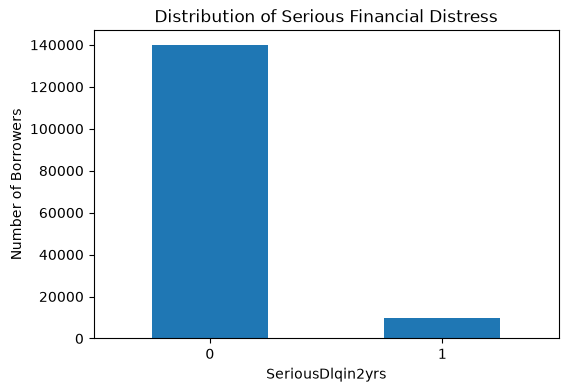

In [6]:
target_counts = df["SeriousDlqin2yrs"].value_counts()

plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")

plt.title("Distribution of Serious Financial Distress")
plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("Number of Borrowers")
plt.xticks(rotation=0)

plt.show()

## Revolving Credit Utilization

Credit utilization measures how much of the available unsecured revolving credit is being used by a borrower.

Higher utilization may indicate greater financial pressure and could therefore be associated with higher credit risk.

In [7]:
df["UtilizationGroup"] = pd.cut(
    df["RevolvingUtilizationOfUnsecuredLines"],
    bins=[-np.inf, 0.25, 0.50, 0.75, 1, np.inf],
    labels=["0-25%", "25-50%", "50-75%", "75-100%", ">100%"]
)

In [8]:
utilization_default = (
    df.groupby(
        "UtilizationGroup",
        observed=False
    )["SeriousDlqin2yrs"]
    .mean()
    * 100
)

utilization_default

UtilizationGroup
0-25%       2.136738
25-50%      5.290905
50-75%     10.127870
75-100%    17.803869
>100%      37.247817
Name: SeriousDlqin2yrs, dtype: float64

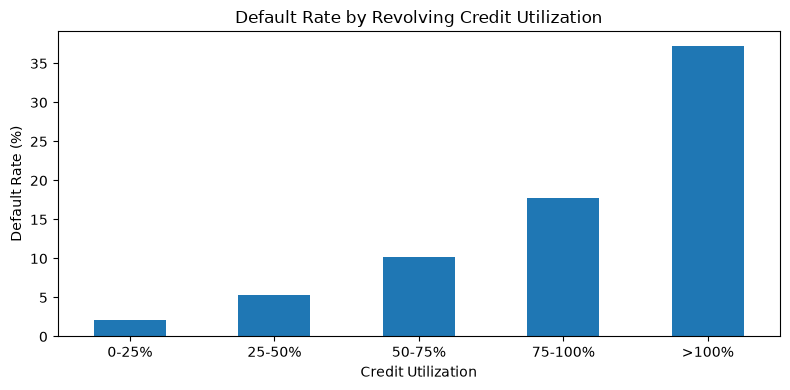

In [9]:
plt.figure(figsize=(8, 4))

utilization_default.plot(kind="bar")

plt.title("Default Rate by Revolving Credit Utilization")
plt.xlabel("Credit Utilization")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../reports/figures/default_rate_by_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

The observed default rate increases substantially as revolving credit utilization rises.

Borrowers using less than 25% of their available revolving credit show relatively low default rates, while borrowers exceeding 100% utilization experience a markedly higher rate of serious financial distress.

This suggests that revolving credit utilization is likely to be an important predictor of credit risk.

In [10]:
df["AgeGroup"] = pd.cut(
    df["age"],
    bins=[20, 30, 40, 50, 60, 70, 80, np.inf],
    labels=["21-30", "31-40", "41-50", "51-60", "61-70", "71-80", "80+"]
)

In [11]:
age_default = (
    df.groupby(
        "AgeGroup",
        observed=False
    )["SeriousDlqin2yrs"]
    .mean()
    * 100
)

age_default

AgeGroup
21-30    11.096446
31-40     9.737026
41-50     8.199766
51-60     6.108187
61-70     3.446892
71-80     2.338951
80+       2.025932
Name: SeriousDlqin2yrs, dtype: float64

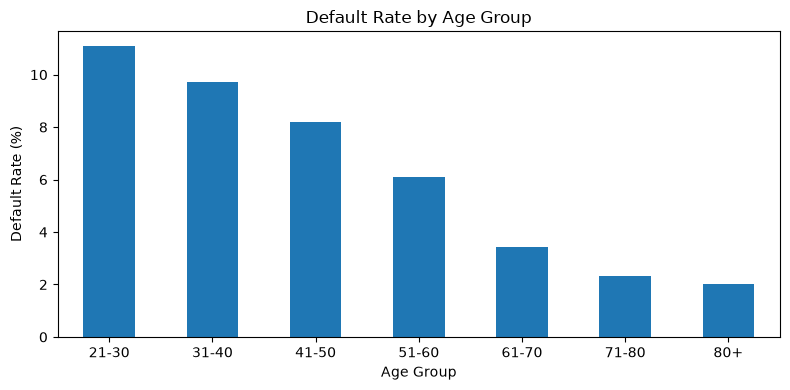

In [12]:
plt.figure(figsize=(8, 4))

age_default.plot(kind="bar")

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../reports/figures/default_rate_by_age.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Default rates decrease consistently across older age groups.

Borrowers between 21 and 30 years old show the highest observed default rate, while borrowers above 60 exhibit substantially lower rates of serious financial distress.

This suggests that age may provide useful predictive information for the credit risk model.

In [13]:
late90_default = (
    df.groupby("NumberOfTimes90DaysLate")["SeriousDlqin2yrs"]
      .agg(["count", "mean"])
)

late90_default["default_rate"] = late90_default["mean"] * 100

late90_default.head(15)

,count,mean,default_rate
NumberOfTimes90DaysLate,,,
0,141661,0.046265,4.626538
1,5243,0.336639,33.663933
2,1555,0.499035,49.903537
3,667,0.577211,57.721139
4,291,0.670103,67.010309
5,131,0.633588,63.358779
6,80,0.600000,60.000000
7,38,0.815789,81.578947
8,21,0.714286,71.428571


In [14]:
df["Late90Group"] = pd.cut(
    df["NumberOfTimes90DaysLate"],
    bins=[-1, 0, 1, 2, 3, np.inf],
    labels=["0", "1", "2", "3", "4+"]
)

In [15]:
late90_group_default = (
    df.groupby(
        "Late90Group",
        observed=False
    )["SeriousDlqin2yrs"]
    .mean()
    * 100
)

late90_group_default

Late90Group
0      4.626538
1     33.663933
2     49.903537
3     57.721139
4+    66.059603
Name: SeriousDlqin2yrs, dtype: float64

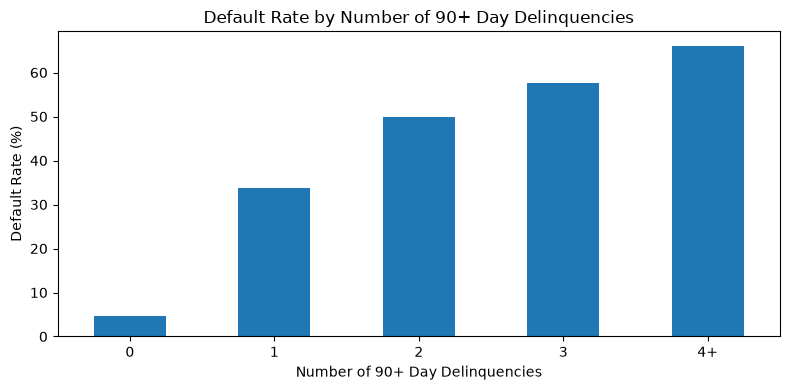

In [16]:
plt.figure(figsize=(8, 4))

late90_group_default.plot(kind="bar")

plt.title("Default Rate by Number of 90+ Day Delinquencies")
plt.xlabel("Number of 90+ Day Delinquencies")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../reports/figures/default_rate_by_90day_delinquency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

The probability of serious financial distress rises sharply as the number of 90+ day delinquencies increases.

Borrowers with no 90+ day delinquencies show relatively low default rates, while borrowers with repeated severe delinquencies exhibit substantially higher credit risk.

This suggests that severe delinquency history is one of the strongest potential predictors in the dataset.

In [17]:
df["Late30Group"] = pd.cut(
    df["NumberOfTime30-59DaysPastDueNotWorse"],
    bins=[-1, 0, 1, 2, 3, np.inf],
    labels=["0", "1", "2", "3", "4+"]
)

late30_default = (
    df.groupby(
        "Late30Group",
        observed=False
    )["SeriousDlqin2yrs"]
    .mean()
    * 100
)

late30_default

Late30Group
0      4.000222
1     15.026198
2     26.511527
3     35.233751
4+    44.578313
Name: SeriousDlqin2yrs, dtype: float64

In [19]:
df["Late60Group"] = pd.cut(
    df["NumberOfTime60-89DaysPastDueNotWorse"],
    bins=[-1, 0, 1, 2, 3, np.inf],
    labels=["0", "1", "2", "3", "4+"]
)

late60_default = (
    df.groupby(
        "Late60Group",
        observed=False
    )["SeriousDlqin2yrs"]
    .mean()
    * 100
)

late60_default

Late60Group
0      5.095685
1     31.006805
2     50.178891
3     56.603774
4+    62.500000
Name: SeriousDlqin2yrs, dtype: float64

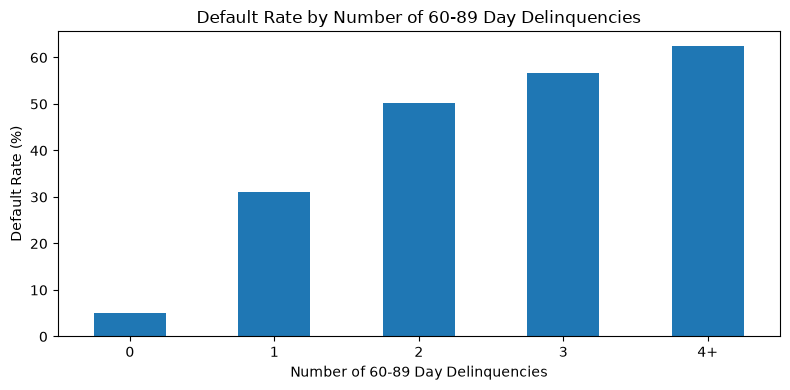

In [20]:
plt.figure(figsize=(8, 4))

late60_default.plot(kind="bar")

plt.title("Default Rate by Number of 60-89 Day Delinquencies")
plt.xlabel("Number of 60-89 Day Delinquencies")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../reports/figures/default_rate_by_60_89day_delinquency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Default rates increase sharply as the number of 60-89 day delinquencies rises.

Borrowers with no recent severe delinquency show relatively low default rates, while repeated 60-89 day delinquencies are associated with substantially higher financial distress.

This confirms that delinquency history contains strong predictive information for credit risk.

In [21]:
income_df = df[df["MonthlyIncome"].notna()].copy()

income_df["IncomeGroup"] = pd.qcut(
    income_df["MonthlyIncome"],
    q=5,
    duplicates="drop"
)

income_default = (
    income_df.groupby(
        "IncomeGroup",
        observed=False
    )["SeriousDlqin2yrs"]
    .agg(["count", "mean"])
)

income_default["default_rate"] = income_default["mean"] * 100

income_default

,count,mean,default_rate
IncomeGroup,,,
"(-0.001, 3000.0]",24976,0.088725,8.872518
"(3000.0, 4550.0]",23077,0.085323,8.532305
"(4550.0, 6313.0]",24020,0.070025,7.002498
"(6313.0, 9083.0]",24028,0.055102,5.510238
"(9083.0, 3008750.0]",24019,0.045048,4.504767


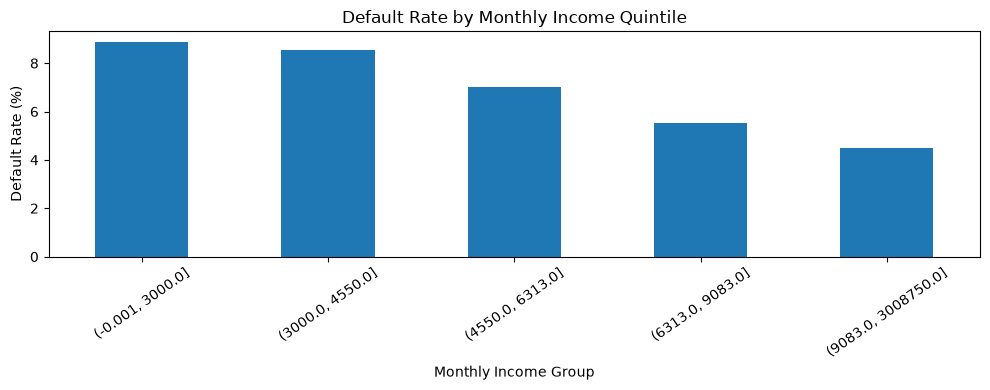

In [22]:
plt.figure(figsize=(10, 4))

income_default["default_rate"].plot(kind="bar")

plt.title("Default Rate by Monthly Income Quintile")
plt.xlabel("Monthly Income Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=35)

plt.tight_layout()

plt.savefig(
    "../reports/figures/default_rate_by_income.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Default rates generally decrease as monthly income increases.

Borrowers in the lowest income groups show higher observed default rates, while higher-income borrowers exhibit lower rates of serious financial distress.

This indicates that monthly income contains useful predictive information, although the relationship should be interpreted alongside other borrower characteristics such as debt burden and delinquency history.

In [23]:
debt_df = df[df["MonthlyIncome"].notna()].copy()

In [24]:
debt_df["DebtRatioGroup"] = pd.qcut(
    debt_df["DebtRatio"],
    q=5,
    duplicates="drop"
)

debt_default = (
    debt_df.groupby(
        "DebtRatioGroup",
        observed=False
    )["SeriousDlqin2yrs"]
    .agg(["count", "mean"])
)

debt_default["default_rate"] = debt_default["mean"] * 100

debt_default

,count,mean,default_rate
DebtRatioGroup,,,
"(-0.001, 0.108]",24024,0.056235,5.623543
"(0.108, 0.237]",24024,0.060897,6.089744
"(0.237, 0.36]",24024,0.053863,5.386280
"(0.36, 0.543]",24024,0.070929,7.092907
"(0.543, 61106.5]",24024,0.102439,10.243923


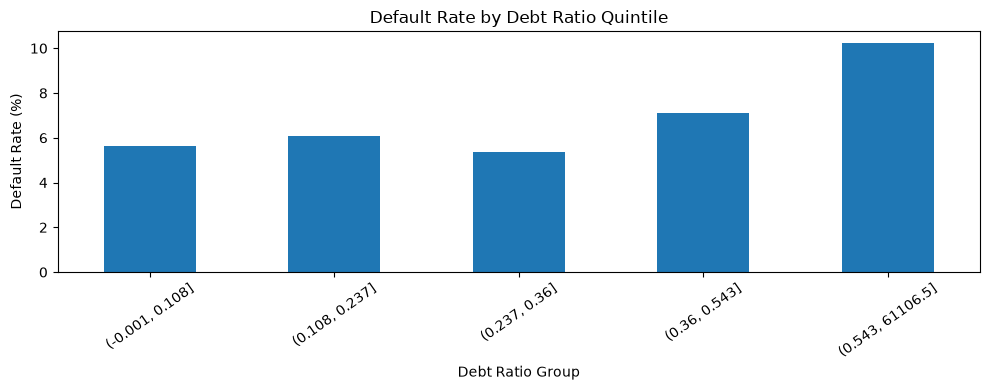

In [25]:
plt.figure(figsize=(10, 4))

debt_default["default_rate"].plot(kind="bar")

plt.title("Default Rate by Debt Ratio Quintile")
plt.xlabel("Debt Ratio Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=35)

plt.tight_layout()

plt.savefig(
    "../reports/figures/default_rate_by_debt_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Default rates do not increase perfectly monotonically across all debt ratio groups.

However, borrowers in the highest debt ratio quintile show a noticeably higher rate of serious financial distress.

This suggests that very high debt burdens may provide useful predictive information, although the relationship is less linear than for variables such as credit utilization or delinquency history.

In [26]:
IncomeMissing = 1

In [27]:
income_missing_default = (
    df.groupby(
        df["MonthlyIncome"].isnull()
    )["SeriousDlqin2yrs"]
    .agg(["count", "mean"])
)

income_missing_default["default_rate"] = (
    income_missing_default["mean"] * 100
)

income_missing_default

,count,mean,default_rate
MonthlyIncome,,,
False,120120,0.068873,6.887279
True,29610,0.054238,5.423843


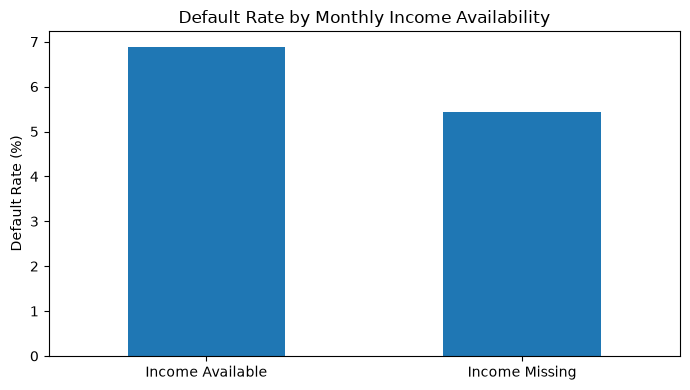

In [28]:
income_missing_plot = income_missing_default["default_rate"].copy()

income_missing_plot.index = [
    "Income Available",
    "Income Missing"
]

plt.figure(figsize=(7, 4))

income_missing_plot.plot(kind="bar")

plt.title("Default Rate by Monthly Income Availability")
plt.xlabel("")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../reports/figures/default_rate_by_income_missing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Borrowers with missing monthly income show a slightly lower observed default rate than borrowers with reported income.

Therefore, missing income should not automatically be interpreted as higher credit risk. However, because income availability is associated with both default behavior and unusual DebtRatio values, the missingness itself may contain useful predictive information.

A missing-income indicator will therefore be retained during preprocessing.